In [1]:
from pathlib import Path
import pandas as pd
from pandas.plotting import scatter_matrix
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import root_mean_squared_error

In [2]:
houses_train = pd.read_csv(Path('data/train.csv'))
houses_test = pd.read_csv(Path('data/test.csv'))

### Data analysis

In [3]:
houses_train.head(5)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
houses_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

There is a lot of missing data in some columns, some of them could be deleted but in case of other we could fill them with data. Additionally, in further pipeline Id column can be used as index of dataset or completely removed.

In [5]:
houses_train.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [6]:
houses_train.shape

(1460, 81)

#### Visualisation of data

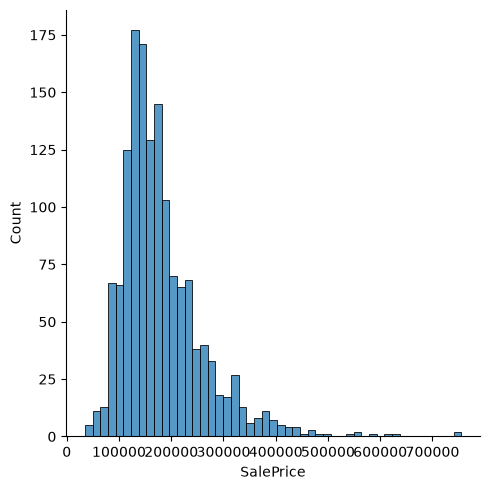

In [7]:
sns.displot(houses_train['SalePrice'])

Prices are clearly right sewed so it will need to be addressed later.

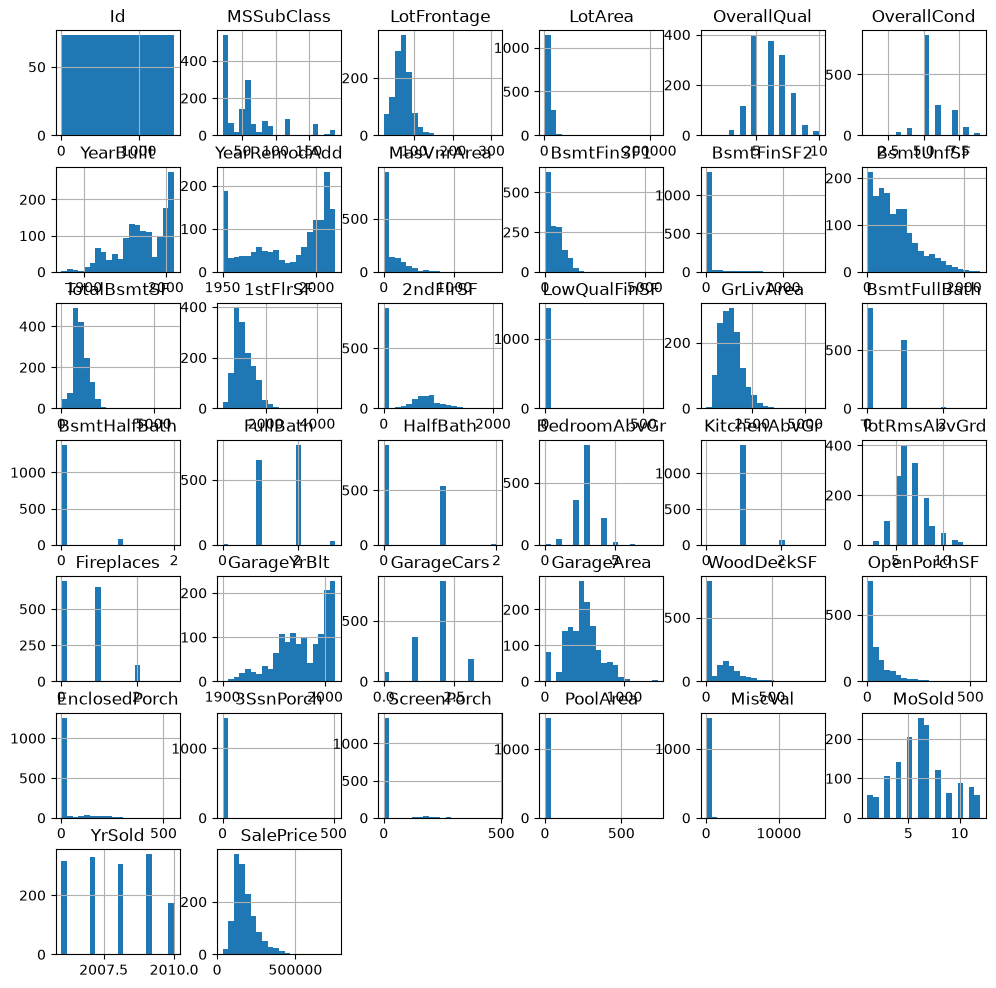

In [8]:
houses_train.hist(bins=20, figsize=(12,12))
plt.show()

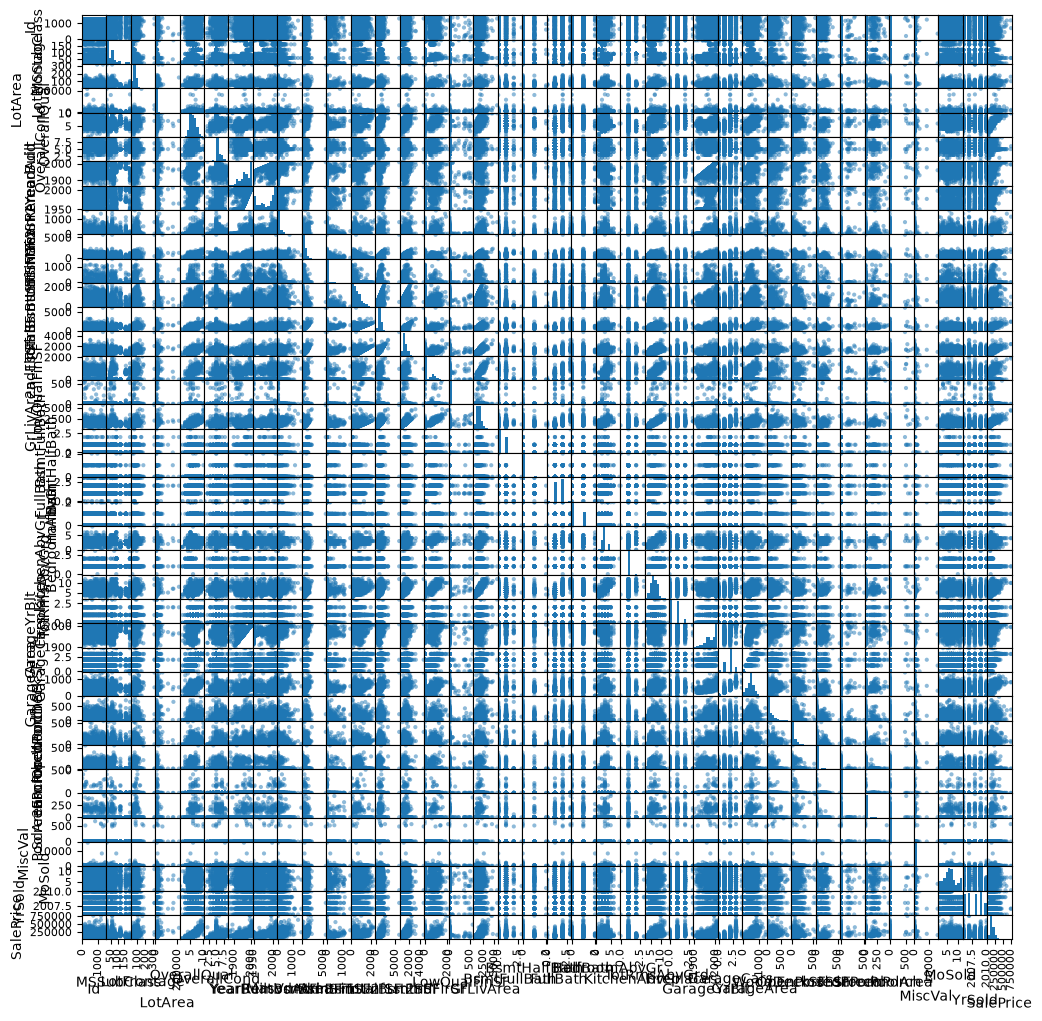

In [9]:
num_attributes = list(houses_train.select_dtypes('number'))
scatter_matrix(houses_train[num_attributes], figsize=(12,12))
plt.show()

That is not usefull let's try correlation matrix

<Axes: >

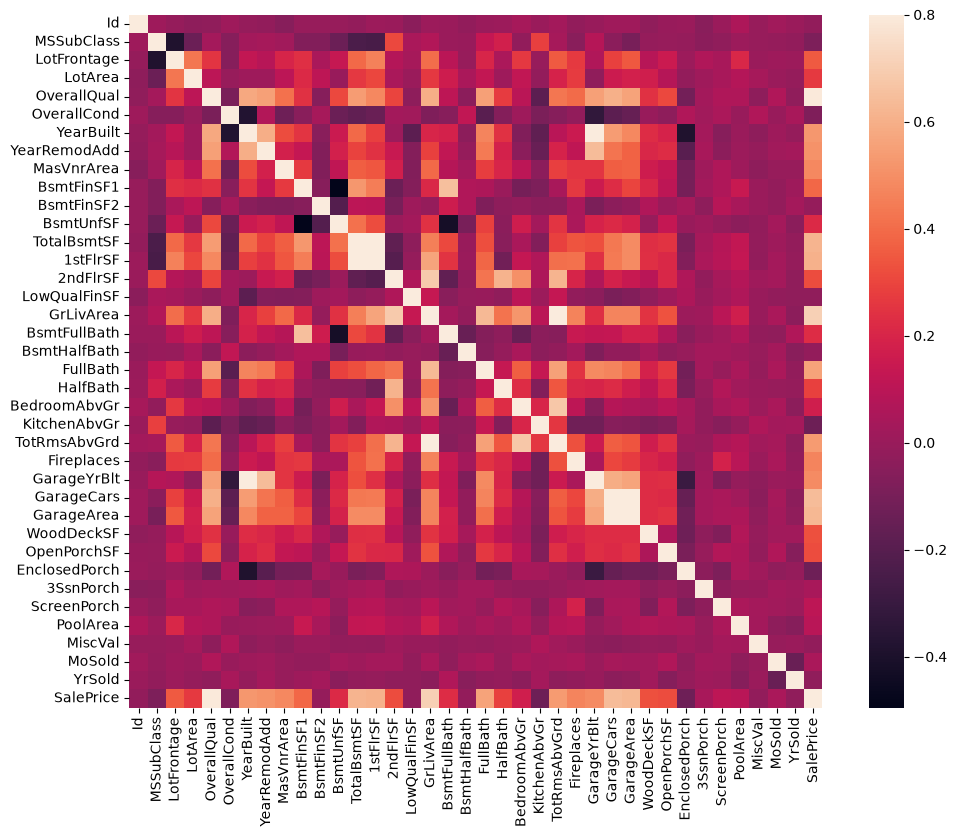

In [10]:
corrmat = houses_train.corr(numeric_only=True)
f, ax = plt.subplots(figsize=(12,9))
sns.heatmap(corrmat, vmax=.8, square=True)

That's better we already can see strong correlation between total square feet of basement area and square feet of first flor. Next strong correlation is between capacity of garage and it's area.

In [11]:
corr_matrix = houses_train.corr(numeric_only=True)

corr_matrix['SalePrice'].sort_values(ascending=False)

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

Most of provided attributes are quite useful but we can try to create new ones.

In [12]:
train_clone = houses_train.copy()

train_clone['Area'] = train_clone['TotalBsmtSF']+train_clone['GrLivArea']+train_clone['GarageArea']+train_clone['WoodDeckSF']+train_clone['OpenPorchSF']+train_clone['EnclosedPorch']+train_clone['3SsnPorch']+train_clone['ScreenPorch']+train_clone['PoolArea']
train_clone['Age'] = train_clone['YrSold']-train_clone['YearBuilt']

corr_matrix = train_clone.corr(numeric_only=True)
corr_matrix['SalePrice'].sort_values(ascending=False)

SalePrice        1.000000
Area             0.807704
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr

New parameters seems to have huge impact on final price of the house so we will need to keep them in mind.

### Handling missing data

In [13]:
train_clone = houses_train.copy()
total = train_clone.isnull().sum().sort_values(ascending=False)
percent = (train_clone.isnull().sum()/train_clone.isnull().count()).sort_values(ascending=False)
missing_data = pd.concat([total, percent], axis=1, keys=['Total', 'Percent'])
missing_data.head(20)

,Total,Percent
PoolQC,1453,0.995205
MiscFeature,1406,0.963014
Alley,1369,0.937671
Fence,1179,0.807534
MasVnrType,872,0.597260
FireplaceQu,690,0.472603
LotFrontage,259,0.177397
GarageQual,81,0.055479
GarageFinish,81,0.055479
GarageType,81,0.055479


I believe there is no point in keeping columns where more than 20% of data is missing, rest of them could be easily filled with most popular instalments.

### Creation of pipeline

As we observed before our pipeline should remove Id column, create new variables, scale all numerical values, transform any objects and lastly remove irrelevant columns and fill rest of them with data.

In [14]:
train_y = np.log1p(houses_train['SalePrice'])
houses_train = houses_train.drop(columns=['SalePrice'])

In [15]:
area_cols = ['TotalBsmtSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea']
age_cols = ['YrSold', 'YearBuilt']
Id_col = ['Id']

all_numeric_cols = houses_train.select_dtypes(include='number').columns.tolist()
remaining_num_cols = [col for col in all_numeric_cols if col not in area_cols + age_cols + Id_col]

class DropColumn(BaseEstimator, TransformerMixin):
    def __init__(self, column):
        self.column = column

    def fit(self,X,y=None):
        return self

    def transform(self, X, y=None):
        return X.drop(columns=self.column, errors='ignore')

class IrrelevantFeature(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.8):
        self.threshold = threshold
        self.cols_to_drop = []

    def fit(self,X,y=None):
        missing_percent = X.isnull().sum() / len(X)
        self.cols_to_drop_ = missing_percent[missing_percent >= self.threshold].index.tolist()
        return self

    def transform(self,X,y=None):
        return X.drop(columns=self.cols_to_drop_, errors='ignore')

def ratio_name(function_transformer, feature_names_in):
    return ['ratio']

def column_sub(X):
    return X[:, [0]] - X[:, [1]]

def variables_adder(X):
    return np.sum(X, axis=1, keepdims=True)

def sum_pipeline():
    return make_pipeline(
        SimpleImputer(strategy='median'),
        FunctionTransformer(variables_adder, feature_names_out=ratio_name),
        StandardScaler()
    )

def cat_pipeline():
    return make_pipeline(
        SimpleImputer(strategy='most_frequent'),
        OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    )

def sub_pipeline():
    return make_pipeline(
        SimpleImputer(strategy='median'),
        FunctionTransformer(column_sub, feature_names_out=ratio_name),
        StandardScaler()
    )

log_pipeline = make_pipeline(
    SimpleImputer(strategy='median'),
    FunctionTransformer(np.log1p, feature_names_out='one-to-one'),
    StandardScaler()
)

master_pipeline = Pipeline([
    ('drop_Id', DropColumn('Id')),
    ('drop_irrelevant', IrrelevantFeature(threshold=0.8)),
    ('preprocessing', ColumnTransformer([
        ('cat', cat_pipeline(), make_column_selector(dtype_include=['object','category'])),
        ('Area', sum_pipeline(), area_cols),
        ('Age', sub_pipeline(), age_cols),
        ('Num', log_pipeline, remaining_num_cols),
    ]
    ))
])

In [16]:
train_X = master_pipeline.fit_transform(houses_train)
train_X.shape

(1460, 265)

### Training models

We will start from using dummy classifier to have better view of rest of the resoults.

In [17]:
dummy_reg = DummyRegressor(strategy='mean')
dummy_reg.fit(train_X, train_y)
dummy_pred = dummy_reg.predict(train_X)
root_mean_squared_error(train_y, dummy_pred)

0.39931245219387496

That is very bad prediction so we can move on to more sophisticated methods like random forest but first let's start with simple tree model.

In [18]:
tree_reg = DecisionTreeRegressor(random_state=42)
tree_reg.fit(train_X, train_y)
tree_pred = tree_reg.predict(train_X)
root_mean_squared_error(train_y, tree_pred)

8.052197378412e-17

In [19]:
sgd_reg = SGDRegressor(random_state=42)
sgd_reg.fit(train_X, train_y)
sgd_pred = sgd_reg.predict(train_X)
root_mean_squared_error(train_y, sgd_pred)

0.19381074690299302

While gradient based model seems to struggle with provided data decision tree seams to be overfitted so let's check it using cross validation.

In [20]:
tree_pipe = Pipeline([('prep', master_pipeline), ('model', DecisionTreeRegressor(random_state=42))])
tree_rmses = -cross_val_score(tree_pipe, houses_train, train_y,
                              scoring='neg_root_mean_squared_error', cv=10)
pd.Series(tree_rmses).describe()

count    10.000000
mean      0.192402
std       0.023960
min       0.152229
25%       0.177377
50%       0.187381
75%       0.213423
max       0.225380
dtype: float64

That is not very good, decision tree model achieves RMSE mean value of 38 202 with standard deviation of 8436. In that case time for more advanced model like random forest regressor.

In [21]:
forest_reg = RandomForestRegressor(random_state=42)
forest_reg.fit(train_X, train_y)
forest_pred = forest_reg.predict(train_X)
root_mean_squared_error(train_y, forest_pred)

0.051285251043920205

In [22]:
forest_pipe = Pipeline([('prep', master_pipeline), ('model', RandomForestRegressor(random_state=42))])
forest_rmses = -cross_val_score(forest_pipe, houses_train, train_y,
                              scoring='neg_root_mean_squared_error', cv=10)
pd.Series(forest_rmses).describe()

count    10.000000
mean      0.134427
std       0.019740
min       0.104505
25%       0.122824
50%       0.134953
75%       0.139957
max       0.175152
dtype: float64

Thats much better our model is not overfitted for our data and achieved better values then basic forest, now we can try to achieve even better score with regularization.

### Model regulation

In [23]:
full_pipeline = Pipeline([
    ('preprocessing', master_pipeline),
    ('forest', RandomForestRegressor(random_state=42))
])

param_grid = [{
    'forest__n_estimators': [100, 300, 500],
    'forest__max_features': [17, 25, 0.7, 1.0],
    'forest__max_depth': [15, 25, 35, None],
    'forest__min_samples_leaf': [1, 2, 4],
    'forest__max_samples': [0.7, 0.8, 1.0]
}]
grid_search = GridSearchCV(full_pipeline, param_grid, cv=5, n_jobs=-1, scoring='neg_root_mean_squared_error')
grid_search.fit(houses_train, train_y)
grid_search.best_params_

{'forest__max_depth': 15,
 'forest__max_features': 0.7,
 'forest__max_samples': 1.0,
 'forest__min_samples_leaf': 1,
 'forest__n_estimators': 500}

In [24]:
cv_res = pd.DataFrame(grid_search.cv_results_)
cv_res.sort_values(by='mean_test_score', ascending=False, inplace=True)
cv_res.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_forest__max_depth,param_forest__max_features,param_forest__max_samples,param_forest__min_samples_leaf,param_forest__n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
74,5.736982,0.050890,0.070448,0.001765,15,0.7,1.0,1,500,"{'forest__max_depth': 15, 'forest__max_feature...",-0.121736,-0.152874,-0.133187,-0.128761,-0.133593,-0.134030,0.010343,1
182,6.431702,0.103313,0.074250,0.005649,25,0.7,1.0,1,500,"{'forest__max_depth': 25, 'forest__max_feature...",-0.121282,-0.153564,-0.132305,-0.128718,-0.134791,-0.134132,0.010732,2
398,6.186138,0.133567,0.081376,0.009841,None,0.7,1.0,1,500,"{'forest__max_depth': None, 'forest__max_featu...",-0.121339,-0.153502,-0.132250,-0.128736,-0.134841,-0.134134,0.010696,3
290,6.336851,0.131350,0.076416,0.001481,35,0.7,1.0,1,500,"{'forest__max_depth': 35, 'forest__max_feature...",-0.121339,-0.153502,-0.132250,-0.128736,-0.134841,-0.134134,0.010696,3
289,3.835606,0.045702,0.051360,0.002279,35,0.7,1.0,1,300,"{'forest__max_depth': 35, 'forest__max_feature...",-0.121791,-0.153639,-0.131981,-0.129574,-0.134376,-0.134272,0.010566,5


In [25]:
-grid_search.best_score_

np.float64(0.13403012526849373)

It looks like our model found best parameters and lowered the standard deviation to only 4148 from previous 7423. So it is time to take our model and predict values of the test set.

In [26]:
final_model = grid_search.best_estimator_
final_prediction = np.expm1(final_model.predict(houses_test))
output = pd.DataFrame({'Id': houses_test['Id'], 'SalePrice': final_prediction})
output.to_csv('House_Prices.csv', index=False)